<h2>Imports</h2>

In [27]:
import numpy as np
import torch
from cellpose import models, denoise, io
from sampleLoad import find_samples, load_sample
import matplotlib.pyplot as plt
from skimage.measure import regionprops

Constants:

In [11]:
SEG_PATH = r"D:\Data\ai4vis\model_weights\cyto3"
DN_PATH  = r"D:\Data\ai4vis\model_weights\denoise_cyto3"
DATA_PATH = r"D:\Data\ai4vis\train_cyto2"
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


<h2>Load data</h2>

256 Paare gefunden in D:\Data\ai4vis\train_cyto2
256 Bilder, 185 verschiedene (H, W)-Kombinationen
H: mean=499.7  median=388.5  std=318.4  min=149  max=2160
W: mean=601.8  median=512.0  std=352.8  min=169  max=2560
Kanäle: {3}


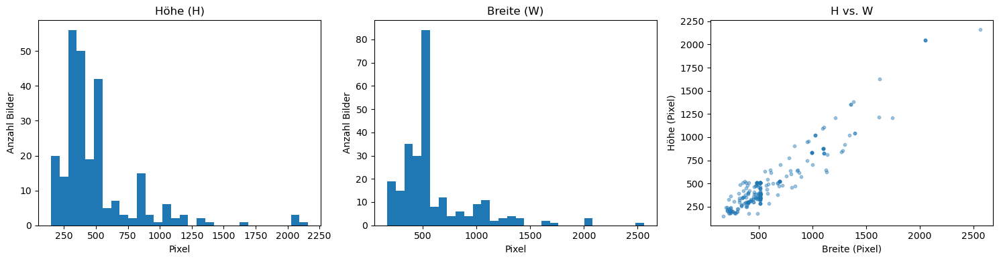

In [24]:
samples = find_samples(DATA_PATH)

heights, widths, channels = [], [], []
for s in samples:
    img, mask = load_sample(s)
    heights.append(img.shape[0])
    widths.append(img.shape[1])
    channels.append(img.shape[2] if img.ndim == 3 else 1)  # 2D-Bild = 1 Kanal

heights, widths = np.array(heights), np.array(widths)

print(f"{len(samples)} Bilder, {len(set(zip(heights, widths)))} verschiedene (H, W)-Kombinationen")
for name, a in [("H", heights), ("W", widths)]:
    print(f"{name}: mean={a.mean():.1f}  median={np.median(a):.1f}  "
          f"std={a.std():.1f}  min={a.min()}  max={a.max()}")
print(f"Kanäle: {set(channels)}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(heights, bins=30)
axes[0].set(title="Höhe (H)", xlabel="Pixel", ylabel="Anzahl Bilder")
axes[1].hist(widths, bins=30)
axes[1].set(title="Breite (W)", xlabel="Pixel", ylabel="Anzahl Bilder")
axes[2].scatter(widths, heights, alpha=0.4, s=10)
axes[2].set(title="H vs. W", xlabel="Breite (Pixel)", ylabel="Höhe (Pixel)")
plt.tight_layout()
plt.show()

<h3>Visualize Data</h3>

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


C:\Users\Peter\anaconda3\envs\aivis\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Peter\anaconda3\envs\aivis\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: C:\Users\Peter\anaconda3\envs\aivis\lib\site-packages\lpips\weights\v0.1\alex.pth
540
Shape Original: (512, 480, 3) | Shape denoised: (512, 480, 2)


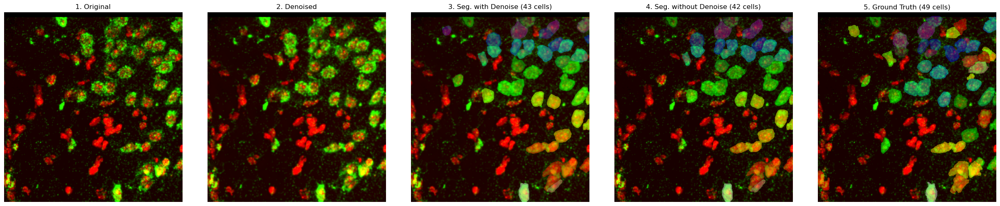

double denoise
Shape Original: (512, 480, 2) | Shape denoised: (512, 480, 2)
original -> denoise 1: {'lpips': 0.6626969575881958, 'ssim': 0.18087204494692682, 'psnr': 3.5210773972346363} 
 denoise 1 -> denoise 2: {'lpips': 0.03426528722047806, 'ssim': 0.9524837565547732, 'psnr': 31.162516242794336}


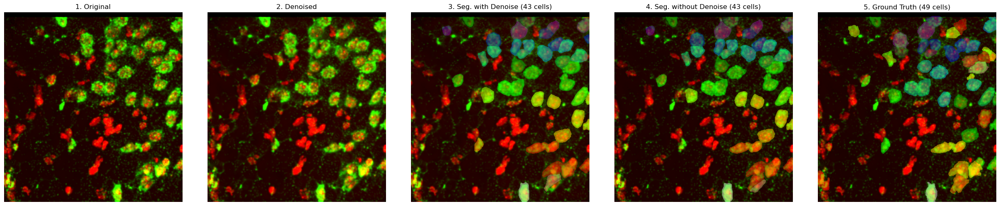

In [81]:
from degradation_analysis import image_metrics, LPIPSScorer
lpip = LPIPSScorer(device=device)

sample = samples[0]
print(sample.name)
img, mask = load_sample(sample)

# cell diam. 
def process_sample(img, mask):
    props = regionprops(mask.astype(int))
    diams = np.array([2 * np.sqrt(p.area / np.pi) for p in props]) # assume: cell is circle
    diam = np.median(diams) if len(diams)> 0 else 30
    
    # --- Denoising: jeden Kanal einzeln, ohne den 30/17-Sonderweg ---
    def denoise_channel(image, c):            # c: 1=R, 2=G, 3=B
        out = dn_model.eval([image], channels=[c, 0], diameter=diam)[0]
        return np.squeeze(out)
    
    cyto_dn = denoise_channel(img, 2)
    nuc_dn  = denoise_channel(img, 1)
    img_dn  = np.stack([cyto_dn, nuc_dn], axis=-1)   # [Zytoplasma, Kern]
    print("Shape Original:", img.shape, "| Shape denoised:", img_dn.shape)  # erwartet (H, W, 2)
    
    # --- Segmentierung ---
    kw = dict(diameter=diam, flow_threshold=0.4, cellprob_threshold=0.0)
    masks_dn,  _, _ = seg_model.eval(img_dn, channels=[1, 2], **kw)  # Index 1 = Zytoplasma, 2 = Kern
    masks_raw, _, _ = seg_model.eval(img,    channels=[2, 1], **kw)  # Original: G=2, R=1
    return masks_raw, masks_dn, img_dn[...,[1,0]]


# --- Visualisierung ---
def vis_masks(img, img_dn, mask, masks_raw, masks_dn):
    def to_display(img, low=1, high=99):
        """Scale each channel to float [0, 1] with percentiles so imshow works for any dtype/range."""
        x = np.asarray(img, dtype=np.float32)
        if x.ndim == 2:
            x = x[..., None]
        out = np.zeros_like(x)
        for c in range(x.shape[-1]):
            lo, hi = np.percentile(x[..., c], [low, high])
            out[..., c] = np.clip((x[..., c] - lo) / max(hi - lo, 1e-6), 0, 1)
        if out.shape[-1] == 2:  # add an empty third channel for RGB display
            out = np.concatenate([out, np.zeros_like(out[..., :1])], axis=-1)
        return out[..., 0] if out.shape[-1] == 1 else out
    
    def show_with_labels(ax, base, labels, title):
        ax.imshow(to_display(base), cmap="gray")
        ax.imshow(np.ma.masked_equal(labels, 0), cmap="nipy_spectral", alpha=0.5, interpolation="nearest")
        ax.set_title(title)
    
    fig, axes = plt.subplots(1, 5, figsize=(25, 5))
    axes[0].imshow(to_display(img), cmap="gray");    axes[0].set_title("1. Original")
    axes[1].imshow(to_display(img_dn), cmap="gray"); axes[1].set_title("2. Denoised")
    show_with_labels(axes[2], img_dn, masks_dn,  f"3. Seg. with Denoise ({masks_dn.max()} cells)")
    show_with_labels(axes[3], img,    masks_raw, f"4. Seg. without Denoise ({masks_raw.max()} cells)")
    show_with_labels(axes[4], img,    mask,      f"5. Ground Truth ({len(np.unique(mask)) - 1} cells)")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

mask_raw, mask_dn, img_dn = process_sample(img,mask)
vis_masks(img,img_dn, mask,mask_raw, mask_dn)
print("double denoise")
mask_raw, mask_dn, img_dn2 = process_sample(img_dn,mask)
img_metric_1 = image_metrics(img[:,:,:-1].squeeze(), img_dn,lpip,"clip")
img_metric_2 = image_metrics(img_dn, img_dn2,lpip,"clip")
print(f"original -> denoise 1: {img_metric_1} \n denoise 1 -> denoise 2: {img_metric_2}")
vis_masks(img_dn,img_dn2, mask,mask_raw, mask_dn)

<h2>Synthetic Noise</h2>

In [45]:
def _per_channel(fn, img: np.ndarray):
    if img.ndim == 2:
        return fn(img)
    return np.stack([fn(np.ascontiguousarray(img[..., c])) for c in range(img.shape[2])], axis=-1)
 
 
def _blur(img: np.ndarray, sigma: float) -> np.ndarray:
    return _per_channel(
        lambda c: cv2.GaussianBlur(c, (0, 0), sigmaX=float(sigma), borderType=cv2.BORDER_REFLECT),
        img.astype(np.float32),
    )
 
 
def _labels_via_float(mask: np.ndarray, fn):
    # OpenCV-Warps unterstuetzen kein int32 -> ueber float32 (exakt bis 2**24 Labels)
    return fn(mask.astype(np.float32)).astype(mask.dtype)
 
 
class Degradation:
    """Wendet Degradierungen auf ein Eingabebild an; geometrische Operationen auch auf die Maske.
 
    Beispiel:
        deg = Degradation(seed=0)
        img, mask = deg.normalize(img, mask)
        img, mask = deg.rotate(img, mask, angle=30)       # Maske wird mitgedreht
        img, mask = deg.poisson_noise(img, mask, scale=5) # Maske bleibt unveraendert
        # oder als Kette:
        img, mask = deg.apply(img, mask, [("normalize", {}), ("gaussian_blur", {"sigma": 3})])
 
    deg.log enthaelt die tatsaechlich verwendeten Parameter jedes Aufrufs (fuer die Auswertung).
    """
 
    OPS = (
        "normalize", "poisson_noise", "gaussian_blur", "downsample",
        "resize", "rescale_to_diameter", "rotate", "rot90", "flip", "random_crop",
    )
 
    def __init__(self, seed = None):
        self.rng = np.random.default_rng(seed)
        self.log: list[dict] = []
 
    def reset_log(self):
        self.log = []
 
    def _log(self, op: str, **params):
        self.log.append({"op": op, **params})
        
    def apply(self, img: np.ndarray, mask = None, steps = ()):
        """steps: Liste aus 'name' oder ('name', {param: wert}) mit name aus Degradation.OPS."""
        for step in steps:
            name, params = (step, {}) if isinstance(step, str) else step
            if name not in self.OPS:
                raise ValueError(f"Unbekannte Operation '{name}'. Erlaubt: {self.OPS}")
            img, mask = getattr(self, name)(img, mask, **params)
        return img, mask
 
    #photometrc
    def normalize(self, img, mask=None, lower: float = 1.0, upper: float = 99.0, clip_low: bool = True):
        """Pro Kanal: lower-Perzentil -> 0, upper-Perzentil -> 1, danach bei 0 geclippt
        (Paper, Methods: noetig, damit Poisson-Rauschen erzeugt werden kann)."""
 
        def norm(c: np.ndarray) -> np.ndarray:
            lo, hi = np.percentile(c, [lower, upper])
            if hi - lo < 1e-8:
                return np.zeros_like(c, dtype=np.float32)
            out = (c - lo) / (hi - lo)
            if clip_low:
                out = np.maximum(out, 0)
            return out.astype(np.float32)
 
        self._log("normalize", lower=lower, upper=upper, clip_low=clip_low)
        return _per_channel(norm, img.astype(np.float32)), mask
 
    def poisson_noise(self, img, mask=None, scale = None,alpha: float = 4.0, beta: float = 0.7):
        """Bild * scale -> Poisson-Stichprobe -> / scale.  Kleiner scale = staerkeres Rauschen.
 
        scale=None: scale ~ Gamma(Shape=alpha, Rate=beta) (Paper: alpha=4.0, beta=0.7 Denoising,
        0.1 Deblurring, 0.03 Upsampling; Test-Skalierungen 0.5-80.0).
        ANNAHME: 'varying values of beta' als Rate-Parameter interpretiert (Mittelwert alpha/beta).
        Ein scale pro Bild, fuer alle Kanaele gleich. Negative Werte werden auf 0 geclippt.
        """
        if scale is None:
            scale = float(self.rng.gamma(shape=alpha, scale=1.0 / beta))
        x = np.maximum(img, 0).astype(np.float64) * scale
        noisy = self.rng.poisson(x) / scale
        self._log("poisson_noise", scale=scale)
        return noisy.astype(np.float32), mask
 
    def gaussian_blur(self, img, mask=None, sigma = None,
                      sigma_range: tuple[float, float] = (1.0, 10.0), diameter_ratio: float = 1.0):
        """Isotroper Gauss-Blur. sigma=None: uniform random in sigma_range. Paper: Sigma scaled with cell-diameter -> diameter_ratio."""
        if sigma is None:
            sigma = float(self.rng.uniform(*sigma_range))
        self._log("gaussian_blur", sigma=sigma, diameter_ratio=diameter_ratio)
        return _blur(img, sigma * diameter_ratio), mask
 
    def downsample(self, img, mask=None, factor= None,factor_range: tuple[int, int] = (2, 7), blur_sigma = None):
        """Blur -> Subsampling -> bilineares upsampling to original size. Paper: factor 2-7, Blur-Sigma ~ 0.4 * factor."""
        if factor is None:
            factor = int(self.rng.integers(factor_range[0], factor_range[1] + 1))
        if blur_sigma is None:
            blur_sigma = 0.4 * factor
        h, w = img.shape[:2]
        small = np.ascontiguousarray(_blur(img, blur_sigma)[::factor, ::factor])
        out = _per_channel(lambda c: cv2.resize(c, (w, h), interpolation=cv2.INTER_LINEAR), small)
        self._log("downsample", factor=factor, blur_sigma=blur_sigma)
        return out.astype(np.float32), mask
 
    # geometric (transform mask also)
    @staticmethod
    def estimate_diameter(mask: np.ndarray):
        counts = np.bincount(mask.ravel().astype(np.int64))[1:]
        counts = counts[counts > 0]
        if counts.size == 0:
            raise ValueError("Maske enthaelt keine Labels -> Durchmesser nicht bestimmbar.")
        return float(np.median(2.0 * np.sqrt(counts / np.pi)))
 
    def resize(self, img, mask=None, scale= None,scale_range: tuple[float, float] = (0.75, 1.25)):
        """scale=None: random in scale_range. (Cellpose-paper-aug.: after-noise: 0.75-1.25; before-noise: 0.5-2)."""
        if scale is None:
            scale = float(self.rng.uniform(*scale_range))
        h, w = img.shape[:2]
        new_w, new_h = max(1, round(w * scale)), max(1, round(h * scale))
        out = _per_channel(
            lambda c: cv2.resize(c, (new_w, new_h), interpolation=cv2.INTER_LINEAR),
            img.astype(np.float32),
        )
        if mask is not None:
            mask = _labels_via_float(mask, lambda m: cv2.resize(m, (new_w, new_h), interpolation=cv2.INTER_NEAREST))
        self._log("resize", scale=scale, new_size=(new_h, new_w))
        return out, mask
 
    def rescale_to_diameter(self, img, mask=None, target: float = 30.0, diameter = None):
        """scale that cell-diameter = 'target' px. (30 cyto, 17 nuclei). diameter=None: estimate using mask"""
        if diameter is None:
            if mask is None:
                raise ValueError("Entweder diameter angeben oder eine Maske uebergeben.")
            diameter = self.estimate_diameter(mask)
        self._log("rescale_to_diameter", target=target, diameter=diameter)
        return self.resize(img, mask, scale=target / diameter)
 
    def rotate(self, img, mask=None, angle = None):
        """Bild bilinear, Mask nearest. angle=None: 0-360 random."""
        if angle is None:
            angle = float(self.rng.uniform(0, 360))
        h, w = img.shape[:2]
        M = cv2.getRotationMatrix2D((w / 2.0, h / 2.0), angle, 1.0)
        out = _per_channel(
            lambda c: cv2.warpAffine(c, M, (w, h), flags=cv2.INTER_LINEAR,
                                     borderMode=cv2.BORDER_CONSTANT, borderValue=0),
            img.astype(np.float32),
        )
        if mask is not None:
            mask = _labels_via_float(mask, lambda m: cv2.warpAffine(
                m, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0))
        self._log("rotate", angle=angle)
        return out, mask
 
    def rot90(self, img, mask=None, k = None):
        """k*90°. k=None: 0-3 random."""
        if k is None:
            k = int(self.rng.integers(0, 4))
        self._log("rot90", k=k)
        out = np.ascontiguousarray(np.rot90(img, k, axes=(0, 1)))
        return out, (None if mask is None else np.ascontiguousarray(np.rot90(mask, k, axes=(0, 1))))
 
    def flip(self, img, mask=None, horizontal = None, vertical = None):
        """None = 50 % prob."""
        horizontal = bool(self.rng.random() < 0.5) if horizontal is None else horizontal
        vertical = bool(self.rng.random() < 0.5) if vertical is None else vertical
        if horizontal:
            img = img[:, ::-1]
            mask = None if mask is None else mask[:, ::-1]
        if vertical:
            img = img[::-1]
            mask = None if mask is None else mask[::-1]
        self._log("flip", horizontal=horizontal, vertical=vertical)
        return np.ascontiguousarray(img), (None if mask is None else np.ascontiguousarray(mask))
 
    def random_crop(self, img, mask=None, size = (224, 224)):
        ch, cw = (size, size) if isinstance(size, int) else size
        h, w = img.shape[:2]
        pad_h, pad_w = max(0, ch - h), max(0, cw - w)
        if pad_h or pad_w:
            pad = [(0, pad_h), (0, pad_w)] + [(0, 0)] * (img.ndim - 2)
            img = np.pad(img, pad, mode="constant")
            if mask is not None:
                mask = np.pad(mask, pad[:2], mode="constant")
            h, w = img.shape[:2]
        y = int(self.rng.integers(0, h - ch + 1))
        x = int(self.rng.integers(0, w - cw + 1))
        self._log("random_crop", y=y, x=x, size=(ch, cw))
        out = np.ascontiguousarray(img[y:y + ch, x:x + cw])
        return out, (None if mask is None else np.ascontiguousarray(mask[y:y + ch, x:x + cw]))

positive Sample:

337 Läufe (177 verschiedene Einstellungen, bis zu 3 Seeds)
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


C:\Users\Peter\anaconda3\envs\aivis\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Peter\anaconda3\envs\aivis\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: C:\Users\Peter\anaconda3\envs\aivis\lib\site-packages\lpips\weights\v0.1\alex.pth


no seeds found in get_masks_torch - no masks found.                                     | 8/22 [02:09<03:44, 16.04s/it]
no seeds found in get_masks_torch - no masks found.
no seeds found in get_masks_torch - no masks found.█████▋                              | 13/22 [03:29<02:25, 16.20s/it]
no seeds found in get_masks_torch - no masks found.█████████████████████████████▎      | 20/22 [05:28<00:34, 17.25s/it]
Chunks: 100%|██████████████████████████████████████████████████████████████████████████| 22/22 [05:44<00:00, 15.66s/it]



Baseline: AP@0.5 ohne/mit Denoise = 0.804 / 0.840, GT-Zellen = 49, Durchmesser = 34.9px, batch_size = 256
Wertebereich des denoisten Bildes: [-0.06, 1.18]  (für LPIPS/SSIM/PSNR wird auf [0,1] geklippt; weicht das stark von [0,1] ab, cfg.img_norm='own' testen)


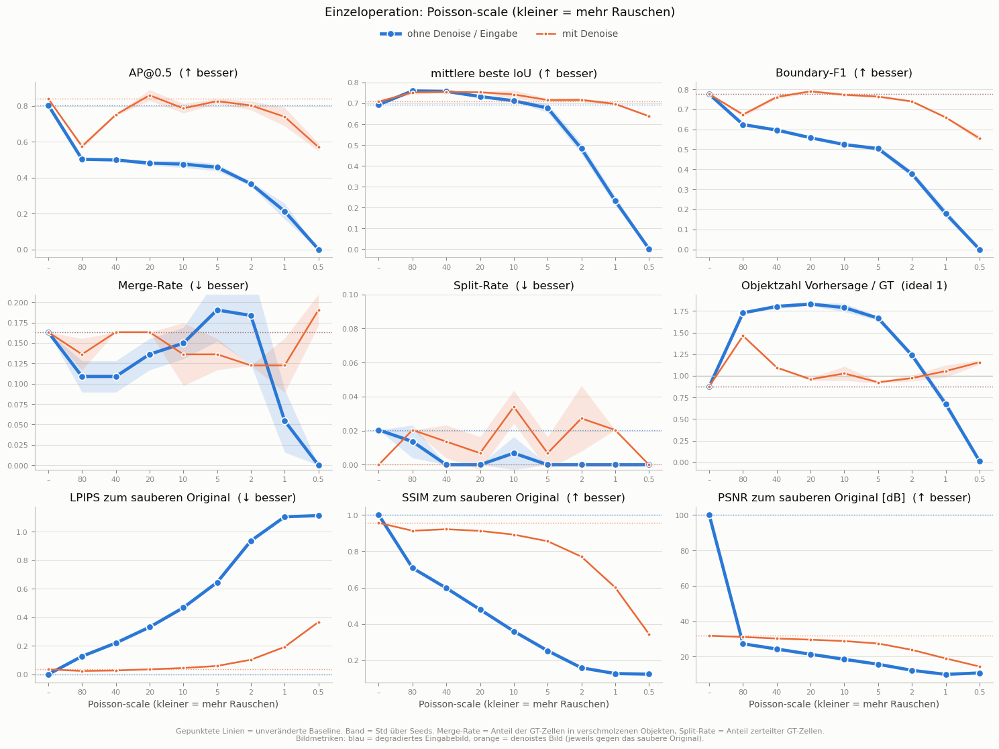

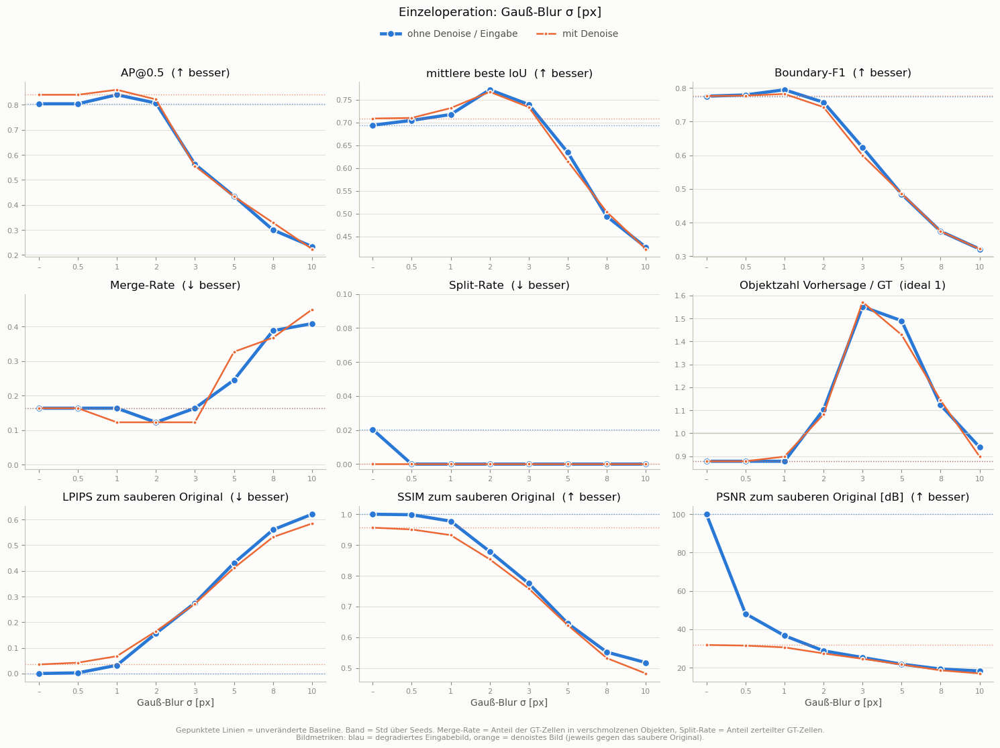

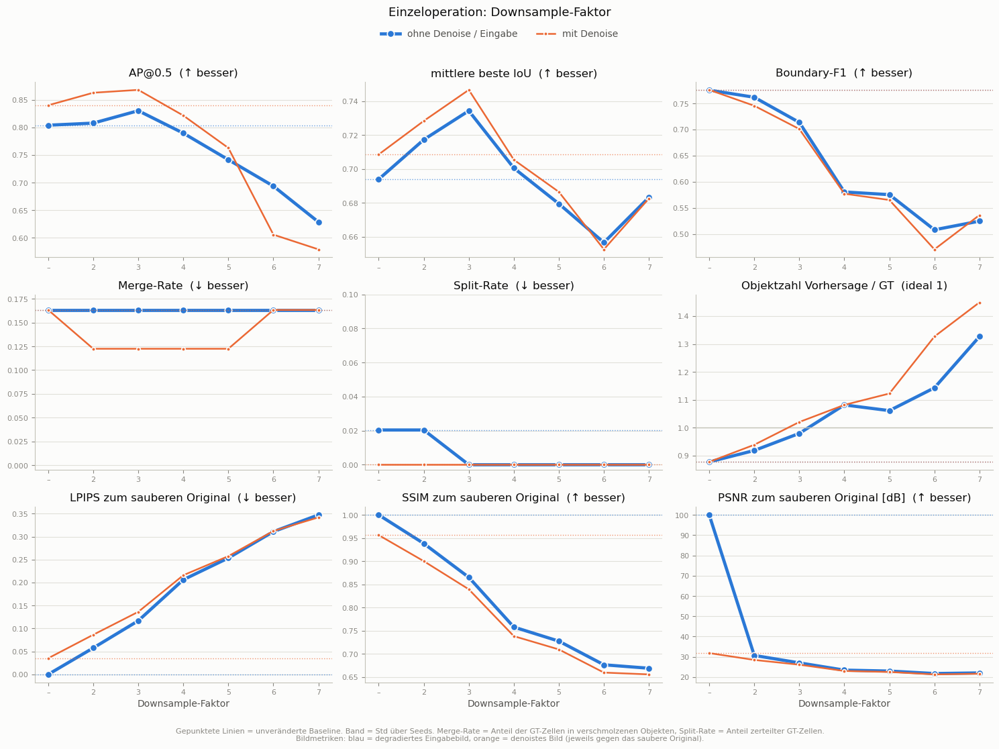

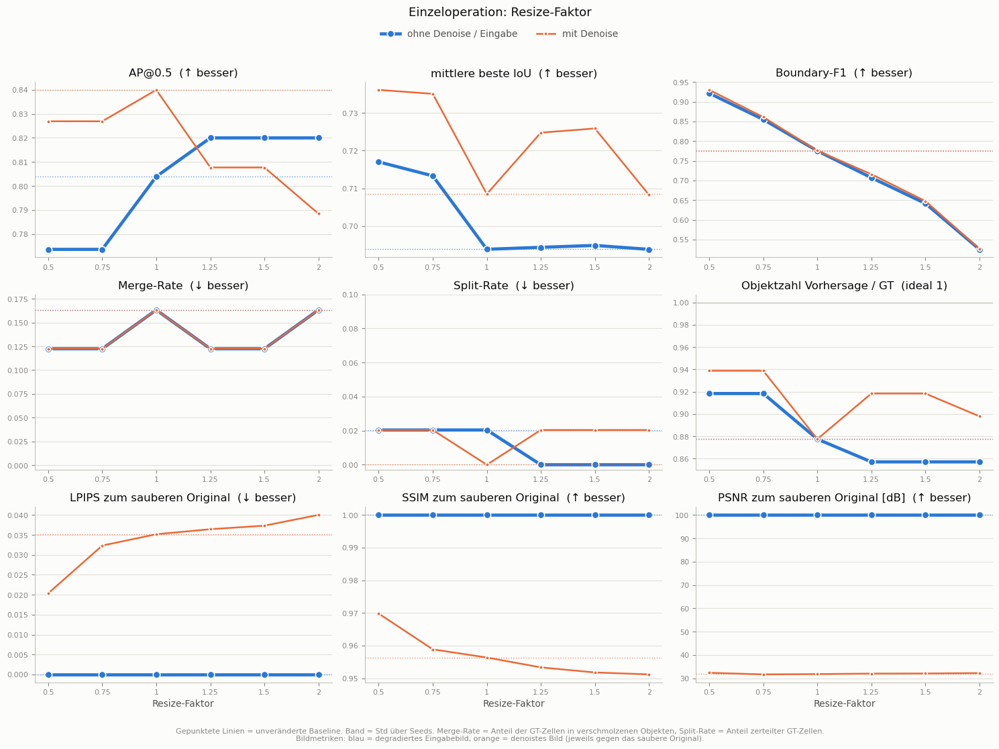

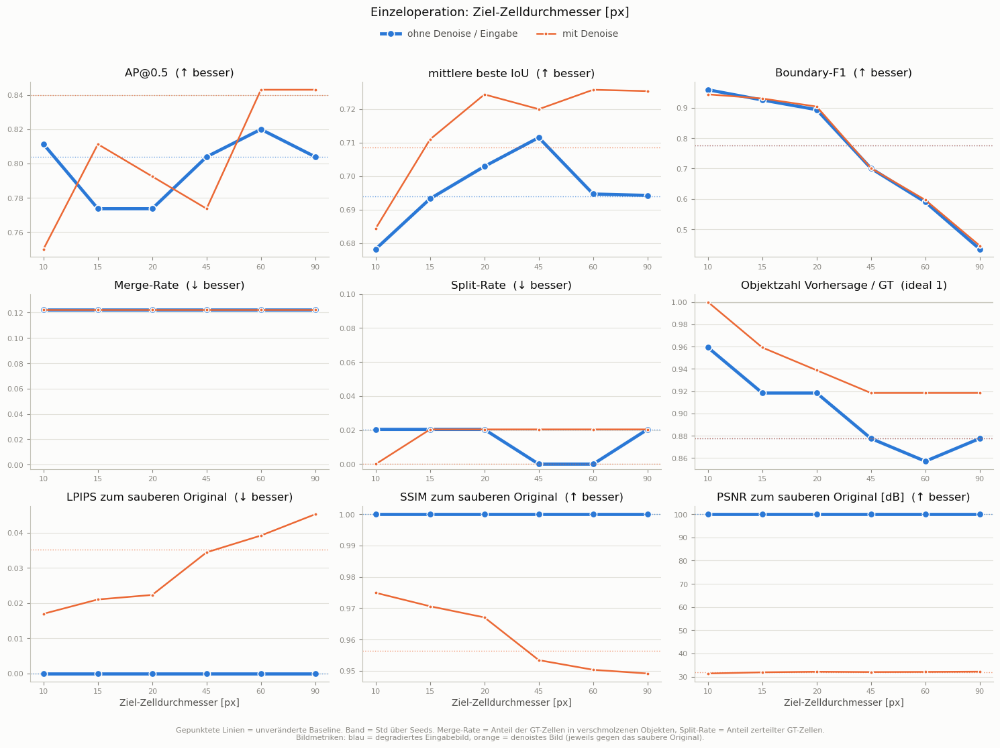

...

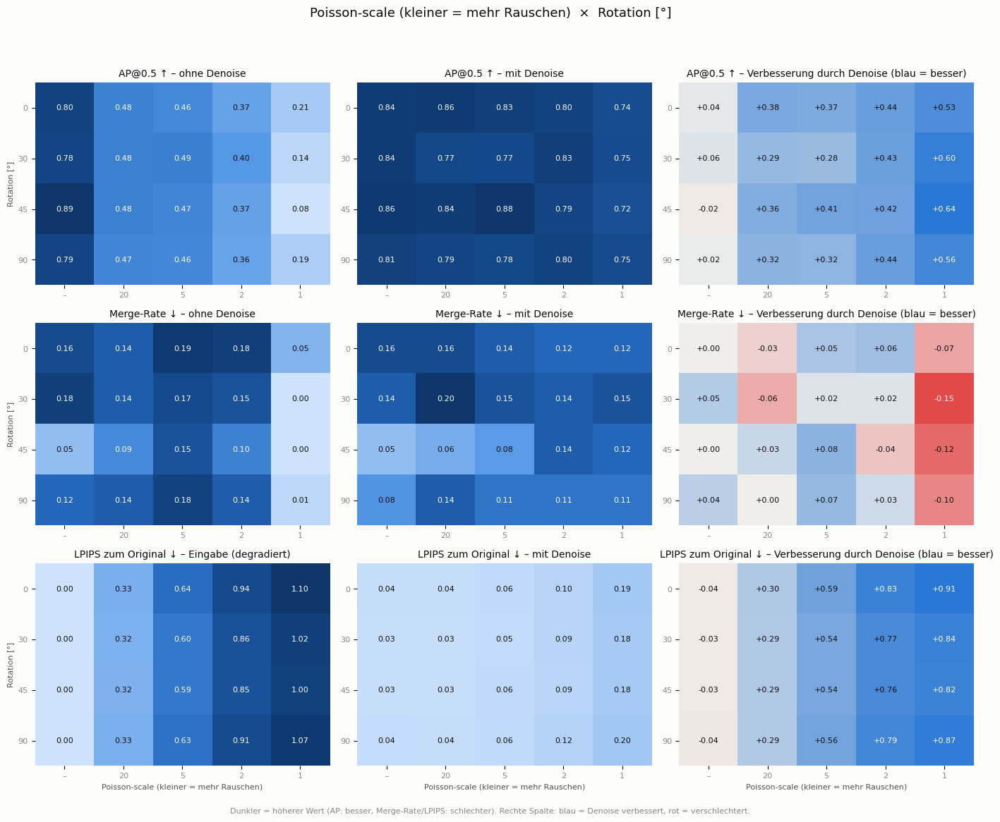

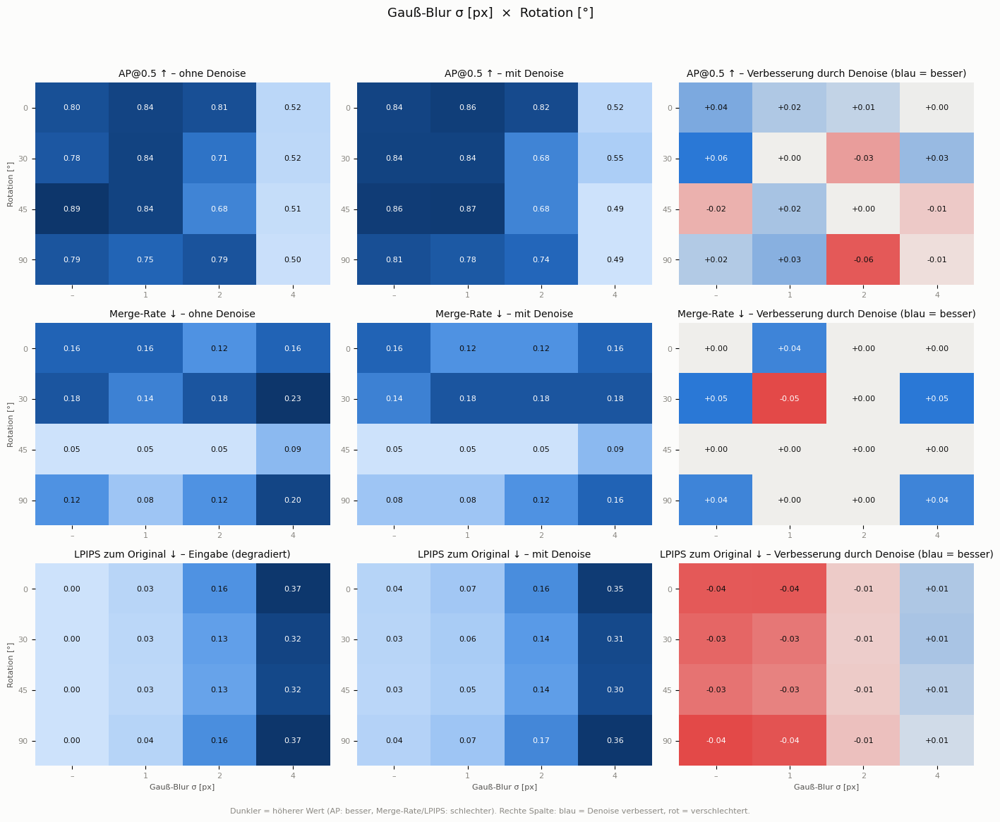

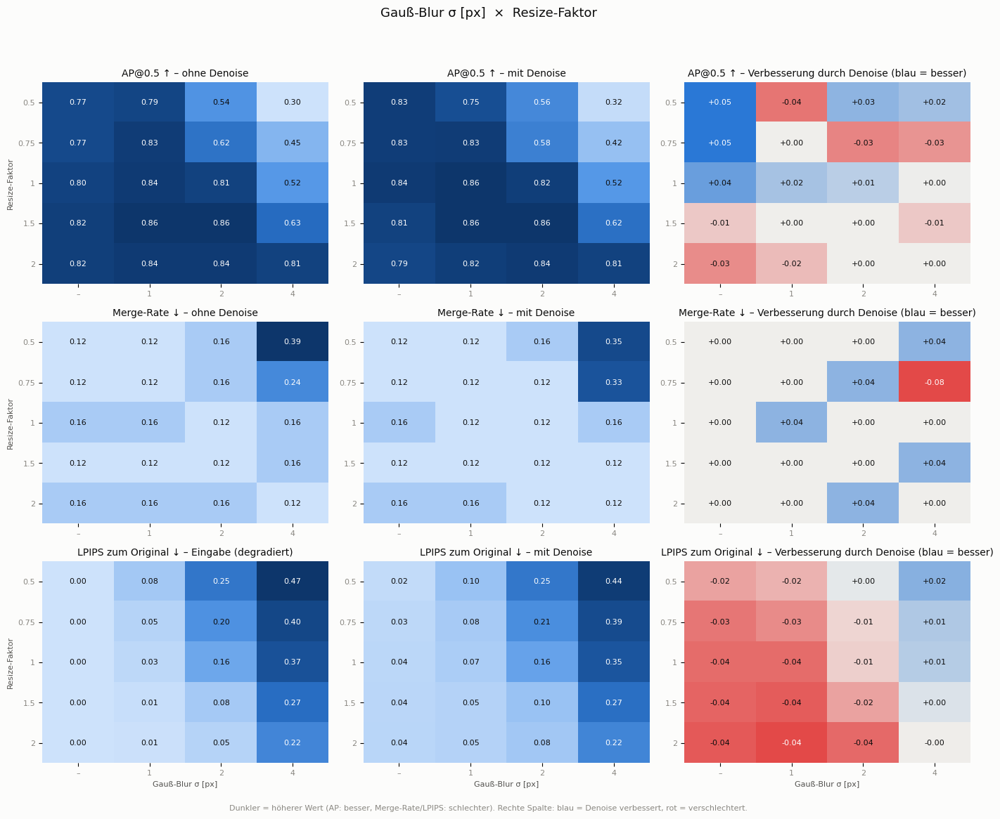

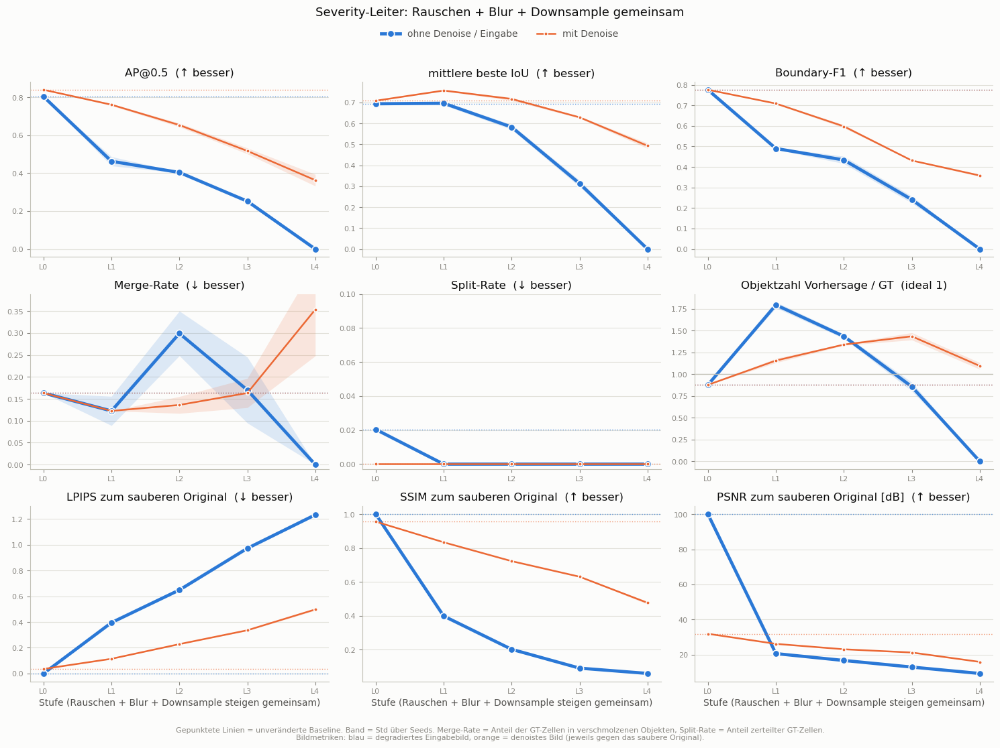

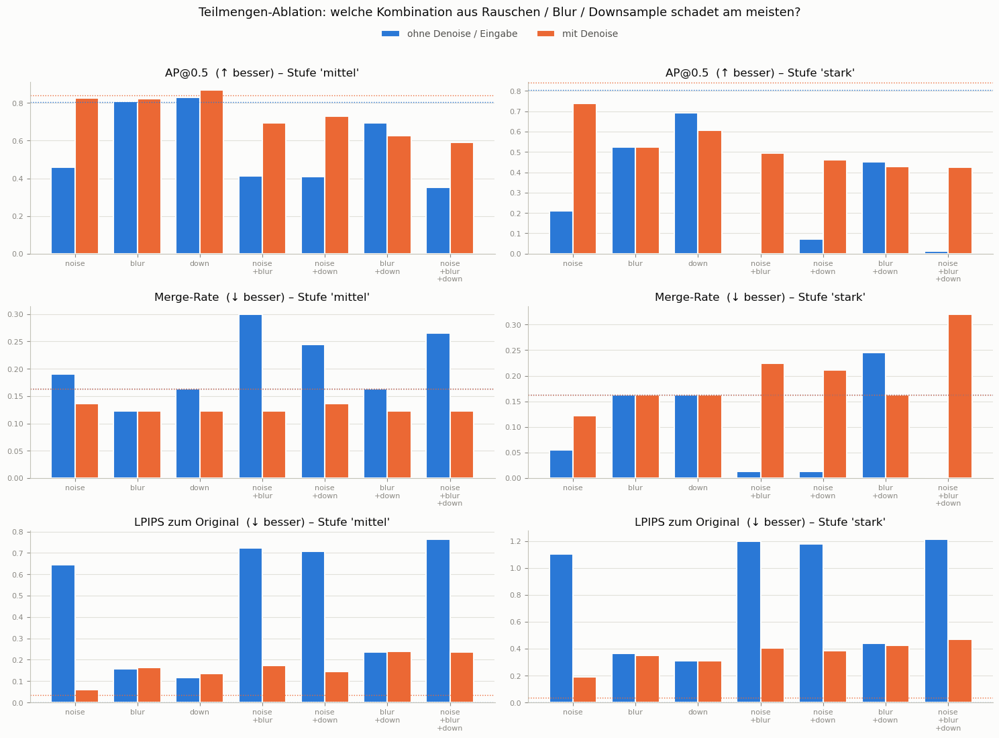


Größte AP@0.5-Einbrüche (ohne Denoise):
                 group                    label  baseline    value     drop
                ladder                       L4  0.803922 0.000000 0.803922
       grid:noisexblur          noise=1, blur=6  0.803922 0.000000 0.803922
          single:noise                      0.5  0.803922 0.000000 0.803922
grid:noisexdiam_factor noise=1, diam_factor=0.5  0.803922 0.000000 0.803922
       grid:noisexblur          noise=1, blur=4  0.803922 0.006667 0.797255
          subset:stark          noise+blur+down  0.803922 0.013469 0.790452
       grid:noisexdown          noise=1, down=7  0.803922 0.033333 0.770588
    single:diam_factor                        3  0.803922 0.040816 0.763105

Größte AP@0.5-Einbrüche (mit Denoise):
                 group                    label  baseline    value     drop
    single:diam_factor                        3      0.84 0.040816 0.799184
    single:diam_factor                     0.25      0.84 0.044444 0.795556
       

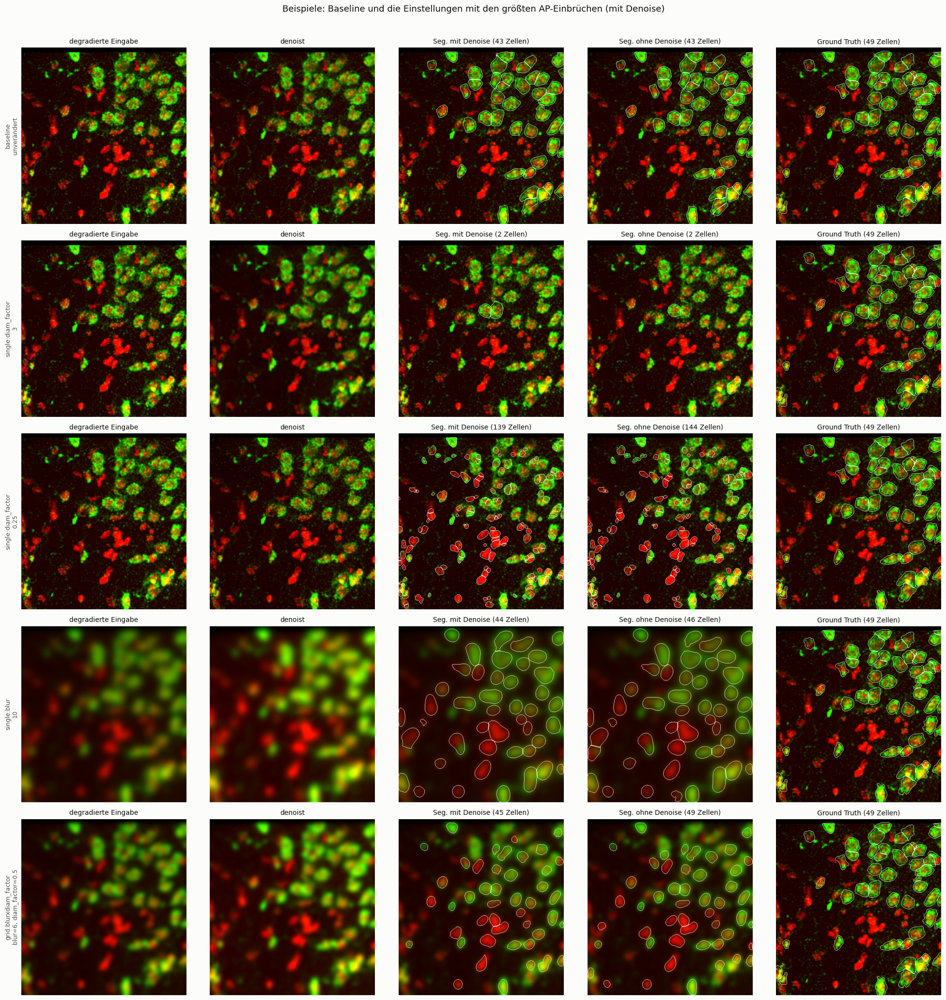

In [58]:
from degradation_analysis import run_analysis
dn_model  = denoise.DenoiseModel(device=device, pretrained_model=DN_PATH)
seg_model = models.CellposeModel(device=device, pretrained_model=SEG_PATH)
res = run_analysis(img_dn, mask, dn_model, seg_model, out_dir="results", n_seeds=3) # use img_dn as "no noise" img

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: C:\Users\Peter\anaconda3\envs\aivis\lib\site-packages\lpips\weights\v0.1\alex.pth
[noise] running 6 condition(s) through both pipelines ...


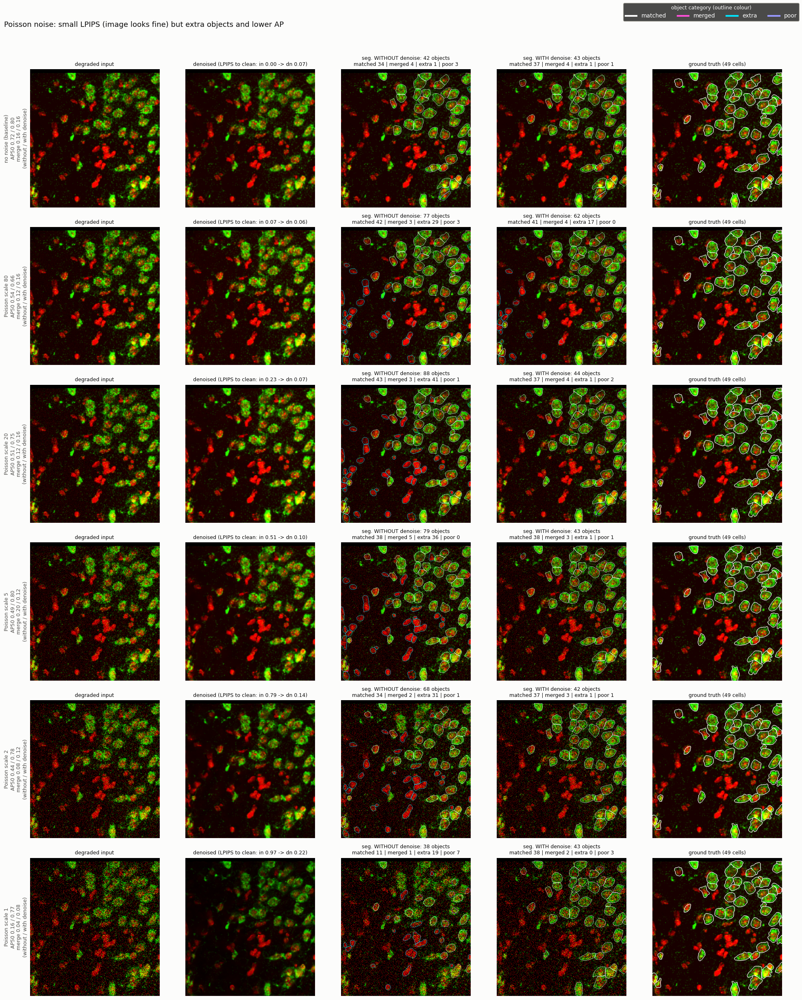

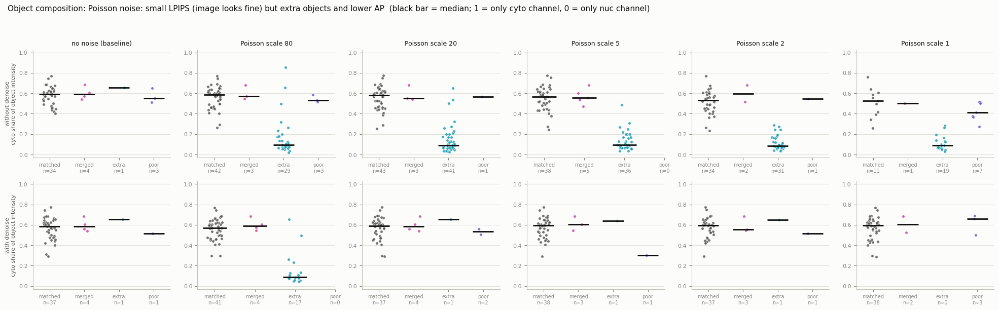

[blur] running 6 condition(s) through both pipelines ...


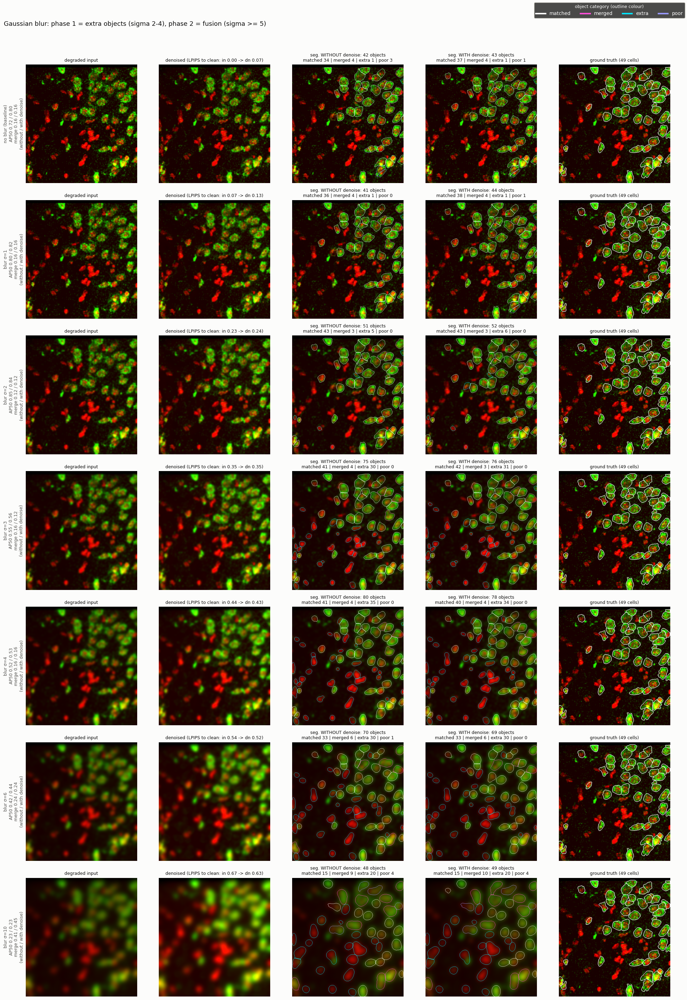

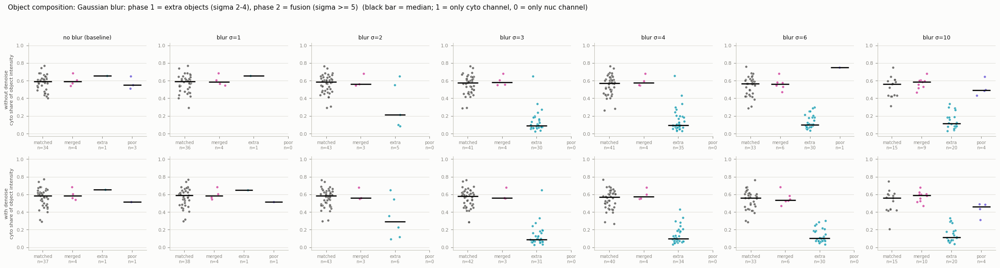

[diameter] running 5 condition(s) through both pipelines ...


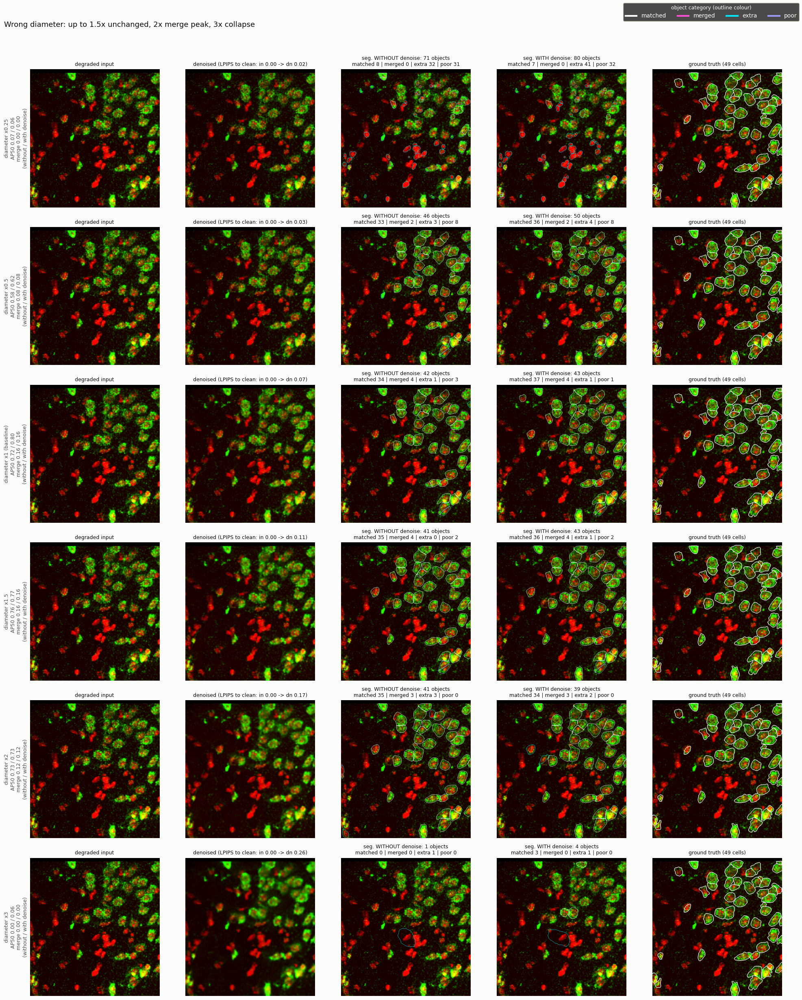

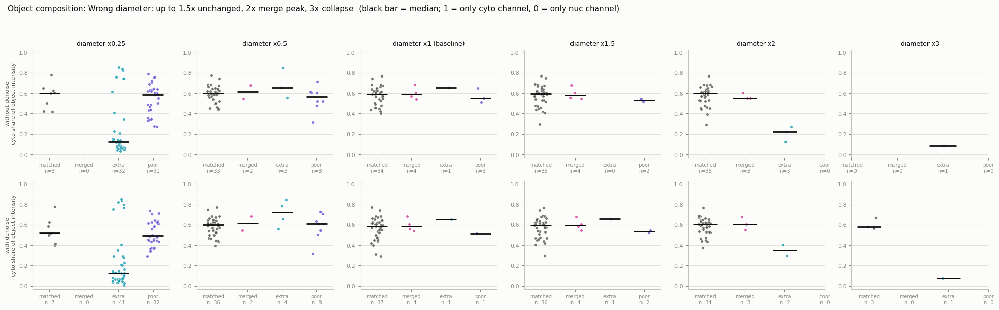

[smoothing] running 7 condition(s) through both pipelines ...


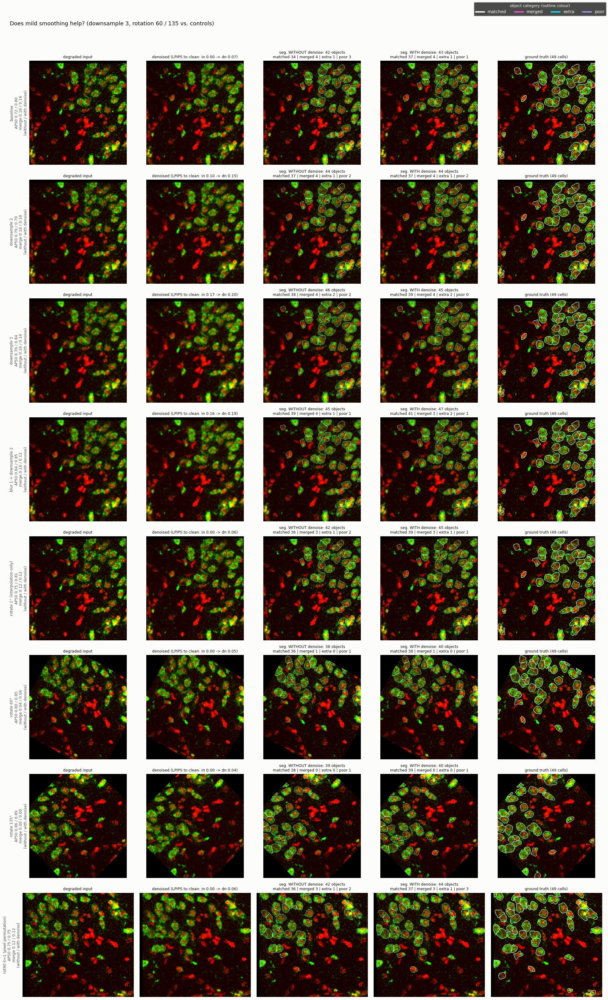

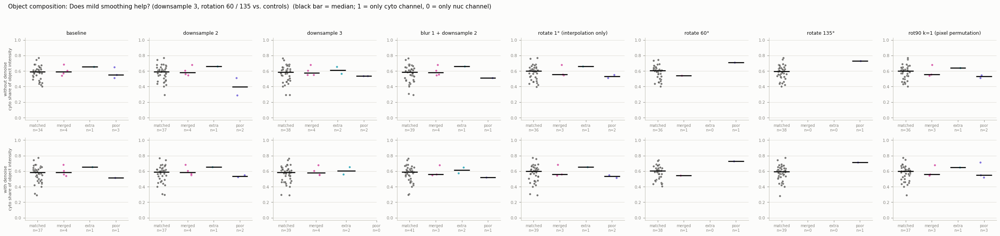

[smoothing-control] running 4 condition(s) through both pipelines ...
[smoothing-control] running 4 condition(s) through both pipelines ...
[smoothing-control] running 2 condition(s) through both pipelines ...
[smoothing-control] running 2 condition(s) through both pipelines ...


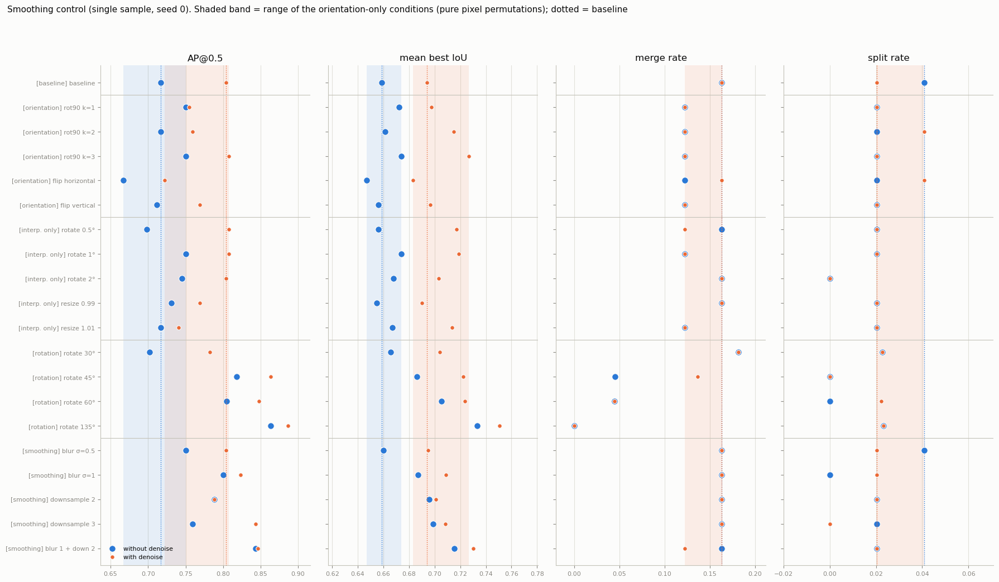


Smoothing control (orientation floor = range over pure pixel permutations):
  AP50 raw: orientation floor 0.667 .. 0.750 | baseline 0.717
  AP50 dn: orientation floor 0.722 .. 0.808 | baseline 0.804
[combo] running 5 condition(s) through both pipelines ...


no seeds found in get_masks_torch - no masks found.


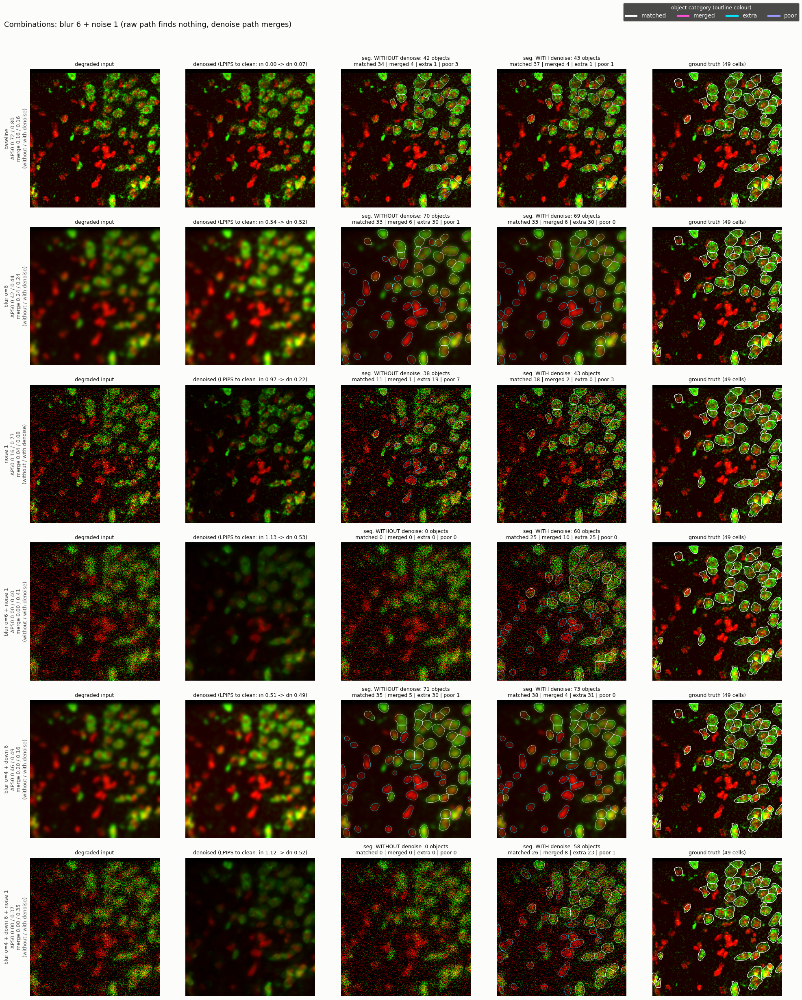

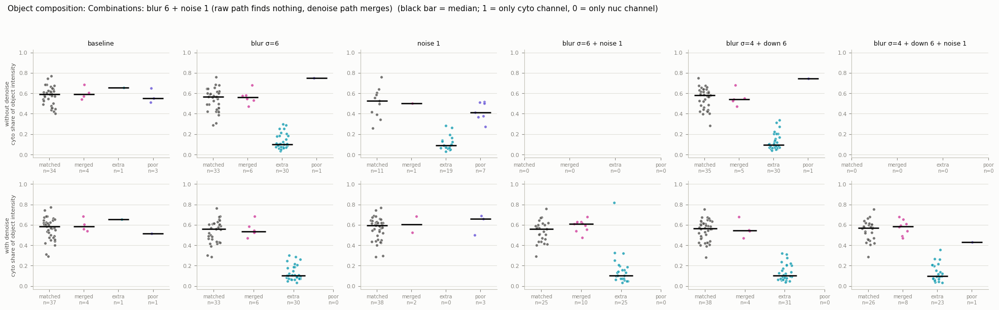

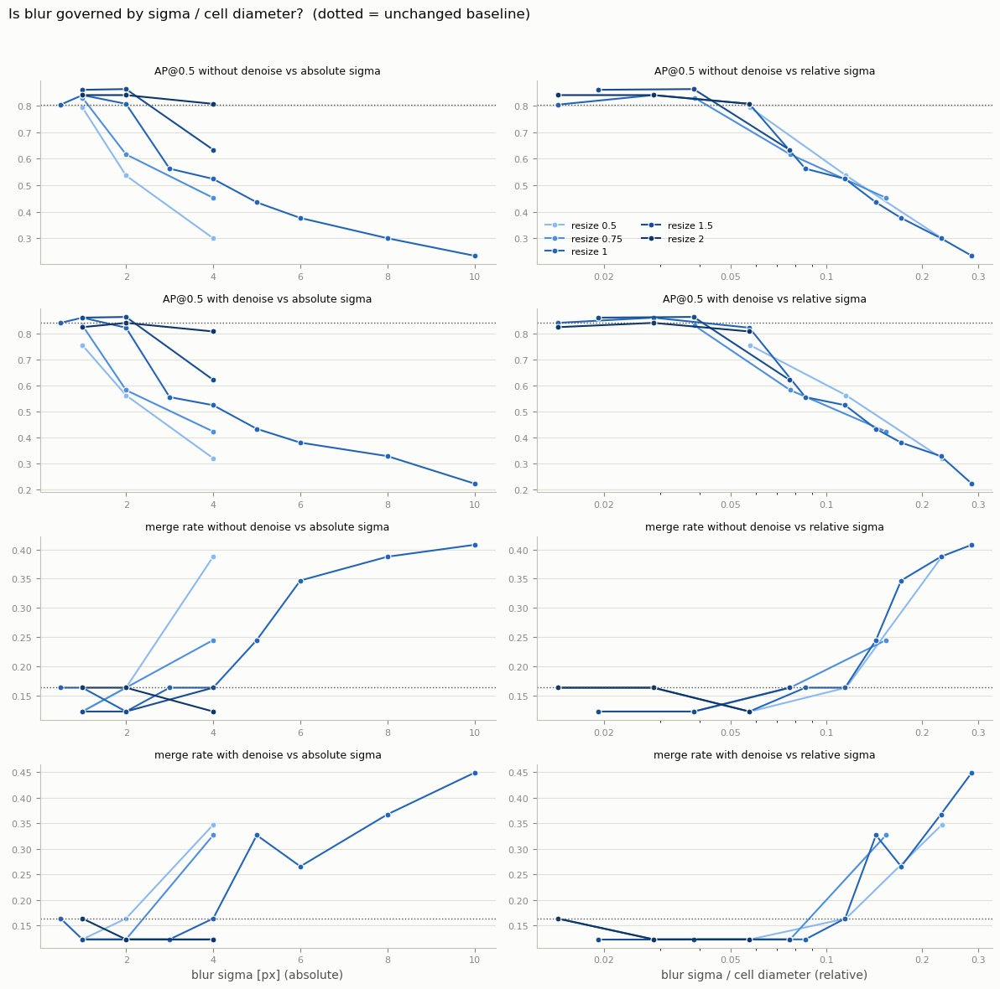


Spearman rank correlation with the metric (|rho| larger = better single predictor):
  raw_ap50         absolute sigma: -0.781 | sigma/d: -0.937  (n=21)
  dn_ap50          absolute sigma: -0.823 | sigma/d: -0.951  (n=21)
  raw_merge_rate   absolute sigma: +0.677 | sigma/d: +0.722  (n=21)
  dn_merge_rate    absolute sigma: +0.606 | sigma/d: +0.685  (n=21)


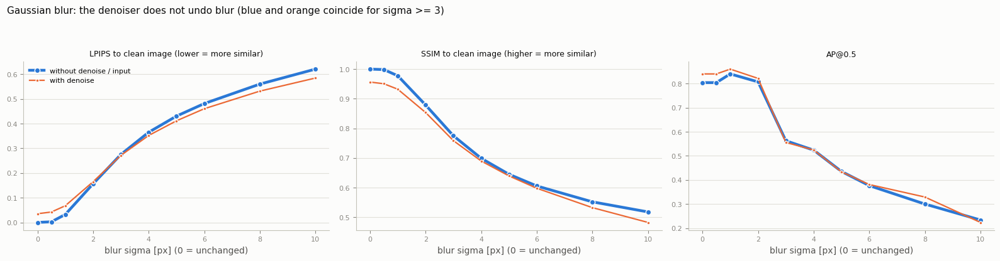


Object categories per condition (path: raw = without denoise, dn = with denoise):
  section                      condition path  n_pred  n_matched  n_merged  n_extra  n_poor  median_cyto_share_matched  median_cyto_share_extra
    noise            no noise (baseline)  raw      42         34         4        1       3                       0.59                     0.66
    noise            no noise (baseline)   dn      43         37         4        1       1                       0.59                     0.65
    noise               Poisson scale 80  raw      77         42         3       29       3                       0.59                     0.10
    noise               Poisson scale 80   dn      62         41         4       17       0                       0.57                     0.09
    noise               Poisson scale 20  raw      88         43         3       41       1                       0.58                     0.09
    noise               Poisson scale 20   dn      44

In [69]:
from inspect_anomalies import run_inspection
run_inspection(img, mask, dn_model, seg_model, results_dir="results")

Mean value (RGB): [60, 40, 0]%
Shape Original: (512, 480, 3) | Shape denoised: (512, 480, 2)


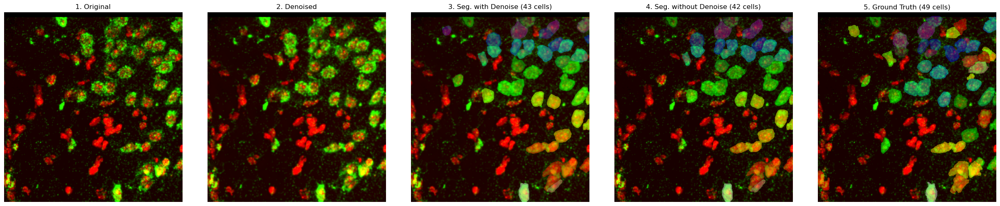

C:\Users\Peter\anaconda3\envs\aivis\lib\site-packages\cellpose\transforms.py:600: UserWarning: 'chan to seg' to seg has value range of ZERO
  warnings.warn("'chan to seg' to seg has value range of ZERO")


Shape Original: (512, 480, 3) | Shape denoised: (512, 480, 2)


C:\Users\Peter\anaconda3\envs\aivis\lib\site-packages\cellpose\transforms.py:602: UserWarning: 'chan2 (opt)' has value range of ZERO, can instead set chan2 to 0
  warnings.warn(


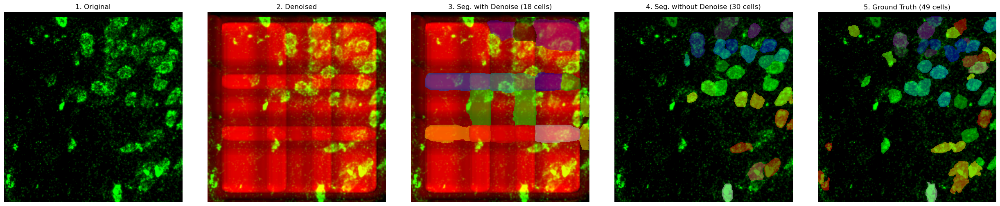

Mean value (RGB): [54, 46, 0]%
Shape Original: (512, 480, 3) | Shape denoised: (512, 480, 2)


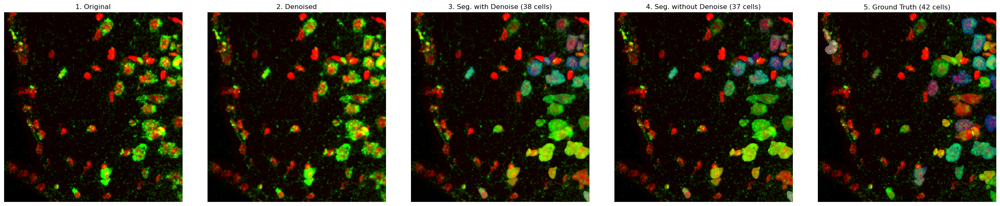

Shape Original: (512, 480, 3) | Shape denoised: (512, 480, 2)


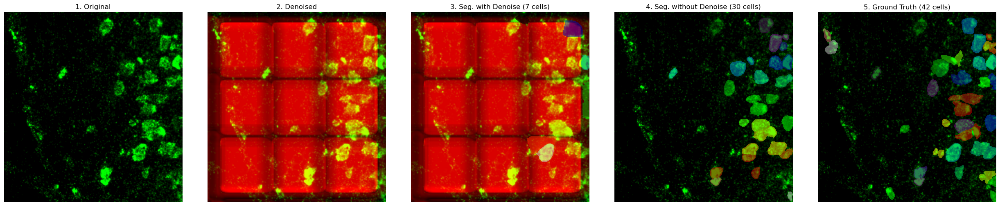

Mean value (RGB): [36, 64, 0]%
Shape Original: (512, 480, 3) | Shape denoised: (512, 480, 2)


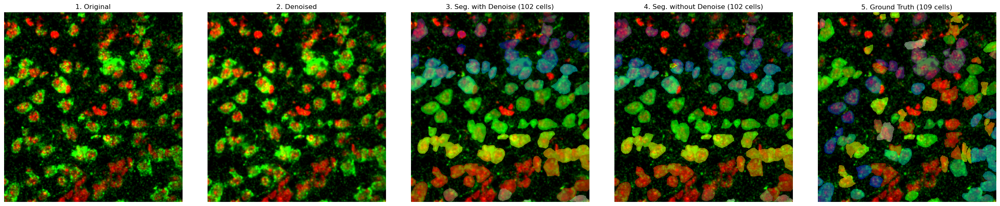

Shape Original: (512, 480, 3) | Shape denoised: (512, 480, 2)


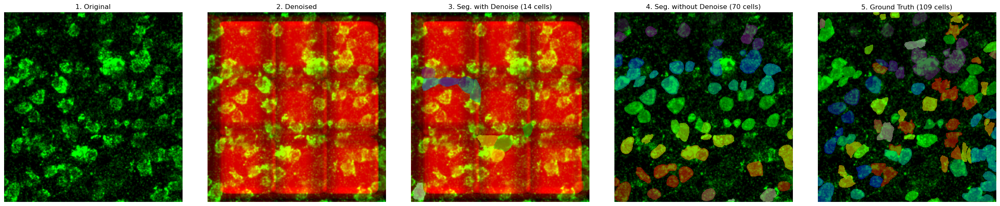

Mean value (RGB): [38, 62, 0]%
Shape Original: (512, 480, 3) | Shape denoised: (512, 480, 2)


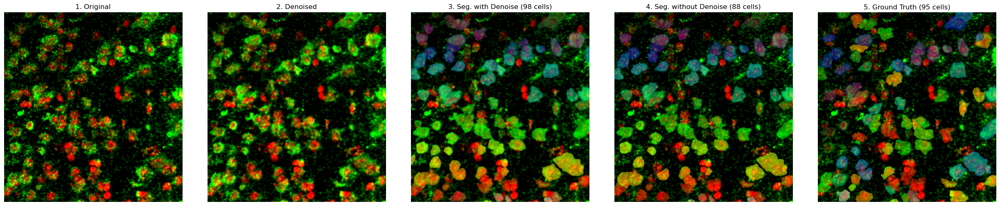

Shape Original: (512, 480, 3) | Shape denoised: (512, 480, 2)


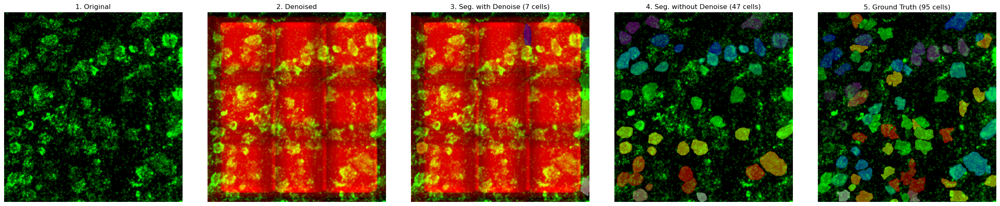

Mean value (RGB): [50, 50, 0]%
Shape Original: (512, 480, 3) | Shape denoised: (512, 480, 2)


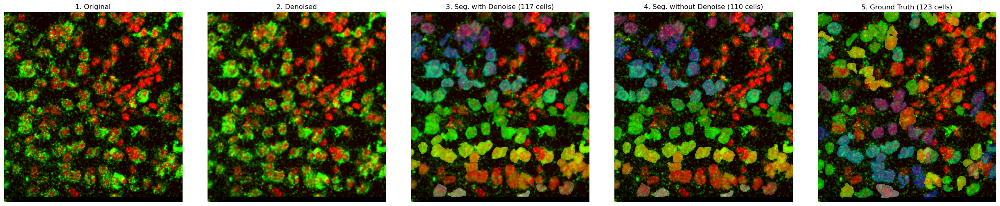

Shape Original: (512, 480, 3) | Shape denoised: (512, 480, 2)


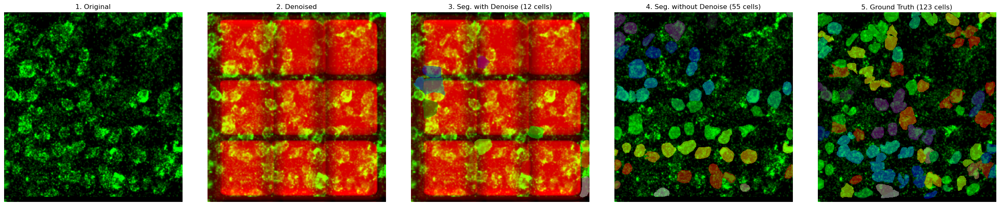

Mean value (RGB): [33, 67, 0]%
Shape Original: (512, 480, 3) | Shape denoised: (512, 480, 2)


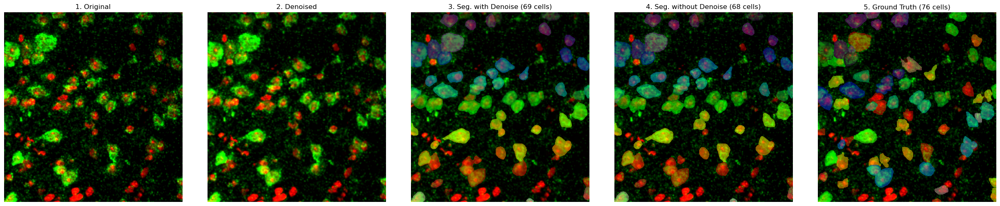

Shape Original: (512, 480, 3) | Shape denoised: (512, 480, 2)


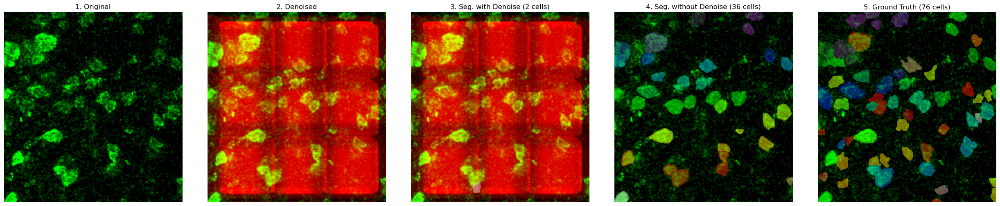

Mean value (RGB): [48, 52, 0]%
Shape Original: (512, 480, 3) | Shape denoised: (512, 480, 2)


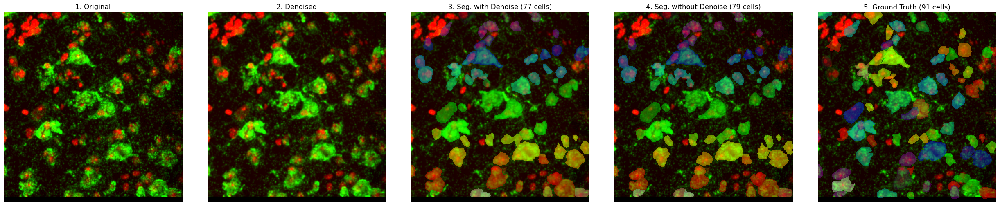

Shape Original: (512, 480, 3) | Shape denoised: (512, 480, 2)


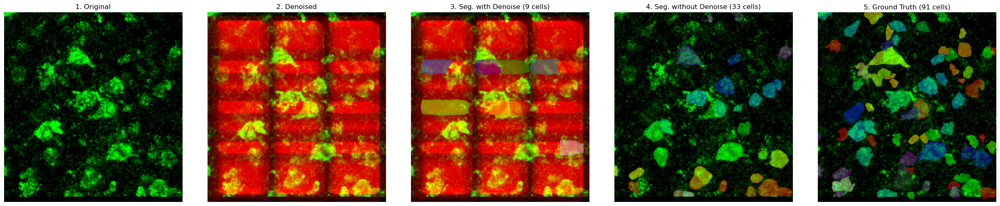

In [98]:
for n in list(np.arange(540,547)):
    nimg, nmask = load_sample(by_name[n])
    mean = np.mean(nimg,axis=(0,1))
    mean_percent = (mean/mean.sum()) * 100
    print(f"Mean value (RGB): {[round(v) for v in mean_percent]}%")
    nmask_raw, nmask_dn, nimg_dn = process_sample(nimg,nmask)
    vis_masks(nimg,nimg_dn, nmask,nmask_raw, nmask_dn)
    nimg[:,:,0] = np.zeros_like(nimg[:,:,0])
    nmask_raw, nmask_dn, nimg_dn = process_sample(nimg,nmask)
    vis_masks(nimg,nimg_dn, nmask,nmask_raw, nmask_dn)

negative Sample:

Mean value (RGB): [21, 79, 0]%
Shape Original: (543, 581, 3) | Shape denoised: (543, 581, 2)


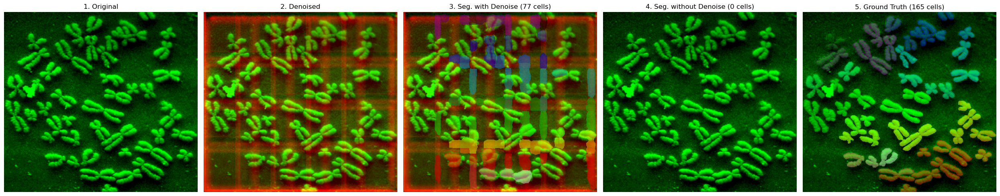

Mean value (RGB): [11, 89, 0]%
Shape Original: (296, 395, 3) | Shape denoised: (296, 395, 2)


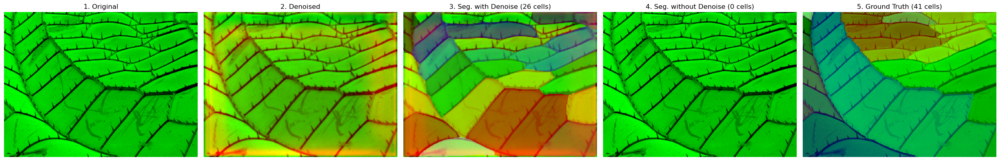

Mean value (RGB): [35, 65, 0]%
Shape Original: (512, 512, 3) | Shape denoised: (512, 512, 2)


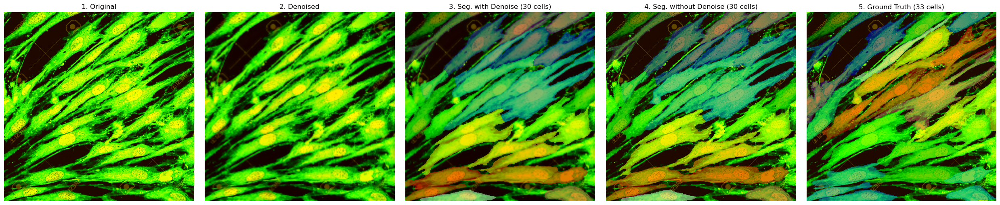

Mean value (RGB): [0, 100, 0]%
Shape Original: (700, 998, 3) | Shape denoised: (700, 998, 2)


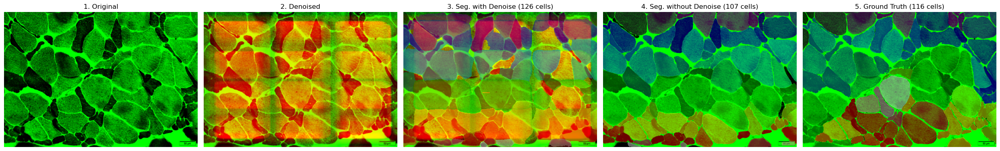

Mean value (RGB): [16, 84, 0]%
Shape Original: (200, 300, 3) | Shape denoised: (200, 300, 2)


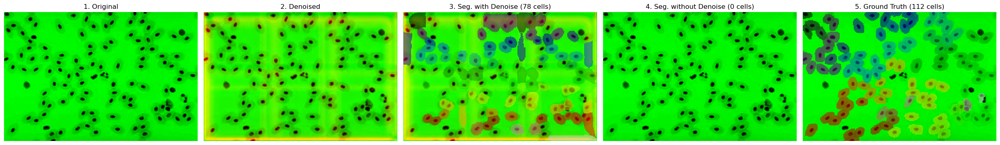

Mean value (RGB): [2, 98, 0]%
Shape Original: (389, 512, 3) | Shape denoised: (389, 512, 2)


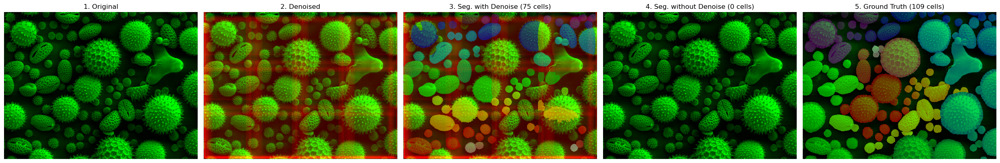

In [96]:
by_name = {int(s.name): s for s in samples}
for n in [557, 558, 559, 560, 564, 568]:
    deg = Degradation(seed=123)
    nimg, nmask = load_sample(by_name[n])
    mean = np.mean(nimg,axis=(0,1))
    mean_percent = (mean/mean.sum()) * 100
    print(f"Mean value (RGB): {[round(v) for v in mean_percent]}%")
    nmask_raw, nmask_dn, nimg_dn = process_sample(nimg,nmask)
    vis_masks(nimg,nimg_dn, nmask,nmask_raw, nmask_dn)
    
    """nimg_poisson, _ = deg.poisson_noise(nimg, scale=20);
    nmask_raw, nmask_dn, nimg_dn = process_sample(nimg_poisson,nmask)
    vis_masks(nimg_poisson,nimg_dn, nmask,nmask_raw, nmask_dn)"""